# Model Interpretability: LIME and SHAP — Part 1 of 2

**This two-part class covers:**

- Business Case
- LIME
  - Global vs. Local Analysis
  - Locality of Interest
  - Model Agnosticism
  - Code Implementation
  - Advantages and Disadvantages
- SHAP
  - Shapley Values
  - Code Implementation

**Today (Part 1):** Business Case, LIME (concept, code implementation, stability check)

**Next time (Part 2):** LIME's Advantages and Disadvantages, SHAP (concept and code implementation)

# Why Trust a Model You Cannot Explain?

A neural network can reach 97% accuracy and still be a model nobody is allowed to use, if nobody can say why it made a particular decision.

**Ask Learners:** Would you let a model deny someone a loan, or diagnose a disease, without being able to explain why?

Most learners vote no, and regulators agree: in healthcare, finance and hiring, an unexplainable decision is often an unusable one. By the end of today's class, you will know **LIME**, one of the most widely used tools for opening up that black box. We will build a real model, generate real explanations, and even catch LIME being less reliable than it looks. Next time, we'll add a second tool, **SHAP**, to the toolkit, and see how it answers LIME's weak spot.

# Business Case

Suppose you work as a data scientist at AIIMS hospital.

You built a neural network model which predicts if a patient has diabetes or not.

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/387/original/Screenshot_2023-09-24_at_1.43.34_PM.png?1695547130 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/388/original/Screenshot_2023-09-24_at_1.43.50_PM.png?1695547232 width=800>

Clearly, we see the gap of how a complex model makes interpretation tough.

**Ask Learners:** The model says "Patient X has diabetes" with 92% confidence. The doctor asks "why?" What would you, as the data scientist, say? Type your answer in the chat.

**Note for Instructor:** Most answers will either dodge the question ("the model is 92% confident") or describe the architecture ("it has three hidden layers"). Neither answers the doctor's actual question: which of this patient's values pushed the prediction toward diabetes. That gap, between what the model can tell us and what a human needs to know, is exactly what this class solves.

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/389/original/Screenshot_2023-09-24_at_1.43.58_PM.png?1695547265 width=800>

# LIME

How do we make a complex model like a neural network interpretable?

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/390/original/Screenshot_2023-09-24_at_1.44.17_PM.png?1695547320 width=800>

- **LIME** (Local Interpretable Model-agnostic Explanations) is used to explain predictions made by machine learning models.
- LIME is a popular technique for interpreting individual predictions of black-box models.
- It approximates the local behavior of a model by creating a local interpretable model, which helps us understand why a model makes a specific prediction for a given instance.

The name LIME is also a map of the three ideas we unpack next: it works on one prediction at a time (**Local**), it can be trusted to explain that one prediction faithfully (**Interpretable**), and it does not care what kind of model it is explaining (**Model-agnostic**).

## Understanding Global Analysis

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/391/original/Screenshot_2023-09-24_at_1.44.34_PM.png?1695547424 width=800>

## Understanding Local Analysis

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/392/original/Screenshot_2023-09-24_at_1.44.49_PM.png?1695547482 width=800>

We just saw the difference between explaining a model's behavior everywhere (global) and explaining one single prediction (local). A global explanation of a neural network with millions of parameters is nearly impossible to state simply. A local explanation, for one patient or one image, is a much smaller and more honest promise, and that is the promise LIME makes.

**Doubt by Learner:** If local explanations are easier, why would anyone ever want a global one?

A doctor treating one patient wants a local explanation. A hospital administrator deciding whether to deploy the model at all wants to know how it behaves across every patient, which is a global question. Both questions are legitimate, LIME simply chooses to answer the local one well rather than the global one badly.

## Understanding Locality of Interest

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/393/original/Screenshot_2023-09-24_at_1.45.02_PM.png?1695547550 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/394/original/Screenshot_2023-09-24_at_1.45.11_PM.png?1695547585 width=800>

These locality of interest points show how fluctuating features affect the model's prediction around the one instance we care about.

**Ask Learners:** If a model's decision boundary is a smooth straight line everywhere, does the local region around a point need to look any different from the rest of the boundary? Type yes or no in the chat.

No, a straight-line boundary looks the same everywhere, zoomed in or zoomed out. LIME's idea only pays off when the boundary is complex overall but can be approximated by something simple, like a straight line, in the small neighborhood around the point we care about. That is exactly the kind of boundary a neural network tends to have.

## Understanding Model Agnosticism

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/395/original/Screenshot_2023-09-24_at_1.45.20_PM.png?1695547621 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/396/original/Screenshot_2023-09-24_at_1.45.27_PM.png?1695547705 width=800>

**Ask Learners:** LIME never looks inside the model's weights, only at its inputs and outputs. What is one advantage, and one disadvantage, of explaining a model this way? Type both in the chat.

**Note for Instructor:** Collect a few answers before revealing these.
- Advantage: the same LIME code explains a neural network, a random forest, or an XGBoost model, with no change to the explainer itself. A data science team does not need a different interpretability tool for every model type.
- Disadvantage: because LIME only watches inputs and outputs, it has to call the model many times (we will see this as `num_samples` in the code), which makes it slower than methods that can look inside the model. It also means LIME can only be as faithful as its perturbation strategy, since it never sees the model's actual reasoning.

## What Has LIME Had to Offer on Model Interpretability?

1. A consistent model-agnostic explainer (LIME).
2. A method to select a representative set with explanations (SP-LIME) to make sure the model behaves consistently while replicating human logic. This representative set provides an intuitive global understanding of the model.

LIME explains a prediction so that even non-experts can compare and improve on an untrustworthy model through feature engineering. An ideal model explainer should contain the following desirable properties.

### Quiz: Local vs Global Explanations

**Question:** A hospital wants to know which single input most often drives the model's diabetes predictions across all ten thousand patients in its database. Which kind of explanation answers this?

- A. A global explanation that summarizes the model's behavior across all patients
- B. A locality-of-interest plot drawn narrowly around just one single prediction point in space
- C. A model-agnostic explanation produced without looking at any patient record
- D. A local explanation generated only for one single representative patient

**Note for Instructor:** Run this as a chat poll. Correct option: A.

The hospital's question is about the model's behavior over the whole patient population, not about any one patient's prediction, so it calls for a global explanation. A locality-of-interest plot and a local explanation are, by definition, scoped to one instance. Model-agnostic describes how an explainer works, not whether its scope is local or global.

# Summarizing LIME Process

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/397/original/Screenshot_2023-09-24_at_1.45.35_PM.png?1695547727 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/398/original/Screenshot_2023-09-24_at_1.45.50_PM.png?1695547786 width=800>

Source: https://towardsdatascience.com/decrypting-your-machine-learning-model-using-lime-5adc035109b5

# LIME: Code Implementation

Let's understand more about LIME by looking at a real-time example. We shall use Fashion MNIST for predicting the category of an apparel.

### Setup

Standard PyTorch and plotting imports, plus fixed random seeds so today's results are reproducible.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torchvision
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

## Loading the Dataset

**Fashion MNIST** is a set of Zalando's article images. It has about 70,000 such images of 28x28 pixels, which we use as our dataset.

**Note for Instructor:** `torchvision`'s default Fashion MNIST mirror is sometimes blocked by institutional networks. The cell below fetches the dataset directly from the Zalando Research GitHub mirror, which is reachable from almost anywhere, and then hands the files to `torchvision` to read.

### The Code

The loop below downloads each of the four raw Fashion-MNIST files directly from the GitHub mirror (skipping any file already downloaded) and un-gzips them into `data/FashionMNIST/raw` — exactly where `torchvision` expects to find them.

In [ ]:
import os, urllib.request, gzip, shutil

raw_dir = "data/FashionMNIST/raw"
os.makedirs(raw_dir, exist_ok=True)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion"
files = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
         "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]

for fname in files:
    raw_path = os.path.join(raw_dir, fname)
    if os.path.exists(raw_path):
        continue
    gz_path = raw_path + ".gz"
    urllib.request.urlretrieve(f"{base_url}/{fname}.gz", gz_path)
    with gzip.open(gz_path, "rb") as f_in, open(raw_path, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)


Now that the raw files are in place, `torchvision.datasets.FashionMNIST(..., download=False)` reads them (we already fetched them ourselves, so no download needed here). We convert the images to NumPy and rescale pixel values from 0–255 to 0–1 — the standard rescaling mentioned below — and print the shapes to confirm everything loaded correctly.

In [ ]:
train_ds = torchvision.datasets.FashionMNIST(root="data", train=True, download=False)
test_ds  = torchvision.datasets.FashionMNIST(root="data", train=False, download=False)

train_images = train_ds.data.numpy().astype("float32") / 255.0
train_labels = train_ds.targets.numpy()
test_images  = test_ds.data.numpy().astype("float32") / 255.0
test_labels  = test_ds.targets.numpy()

print("Train Images Shape: ", train_images.shape)
print("Train Labels Shape: ", train_labels.shape)
print("Test Images Shape: ", test_images.shape)
print("Test Labels Shape: ", test_labels.shape)

Train Images Shape:  (60000, 28, 28)
Train Labels Shape:  (60000,)
Test Images Shape:  (10000, 28, 28)
Test Labels Shape:  (10000,)


Let's peek at one image to confirm it loaded correctly.

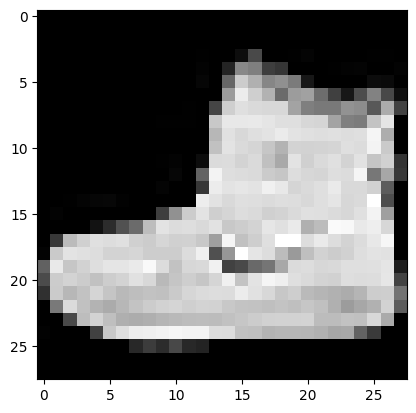

In [ ]:
plt.figure()
plt.imshow(train_images[0], cmap='gray', vmin=0, vmax=1)
plt.grid(False)
plt.show()

Even though we find that the images are blurry, we can still make out the type of apparel (ankle boot) from the figure. Let's see how good a simple neural network is at doing so.

In [ ]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Neural networks are usually not good at dealing with large integers. So, we rescale the image pixels to be in the range [0, 1]. Note that this is a standard technique while dealing with pixels in machine learning. We already did this rescaling when we loaded the data above.

Let's have a look at a number of demo images to see what various apparels in the dataset look like.

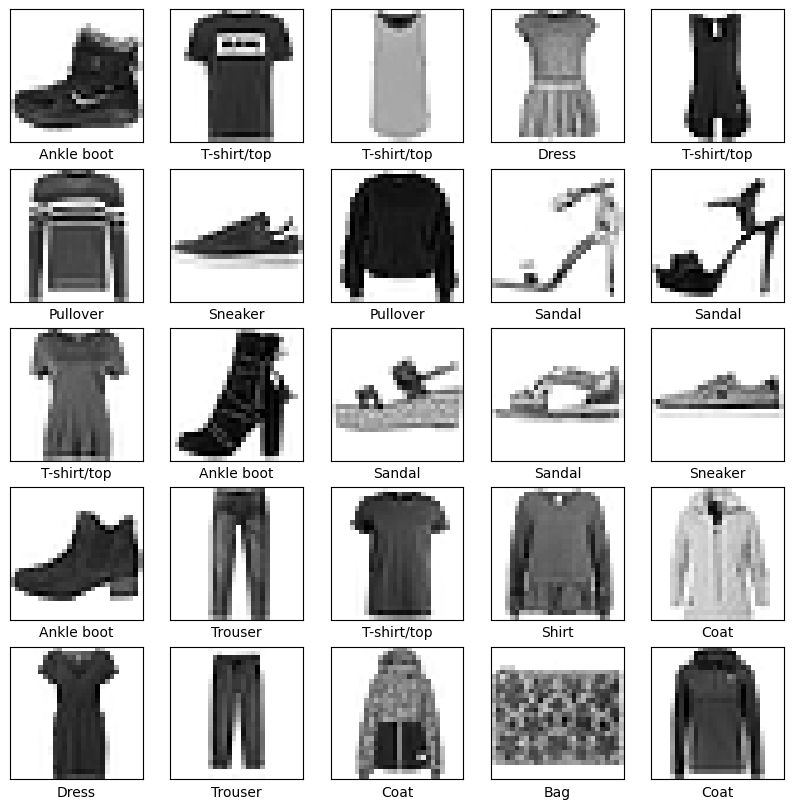

In [ ]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

### Let's Build a Model

Before we go ahead and understand how we interpret a model, we need to train a model. Let's build a simplistic classifier, train it, and evaluate its performance on our dataset.

### The Code

`SimpleNet` is about as simple as an image classifier gets: `nn.Flatten()` turns each 28×28 image into a flat 784-length vector, one `nn.Linear(784, 128)` + `nn.ReLU()` hidden layer, then `nn.Linear(128, 10)` for the 10 class scores — raw logits, since `nn.CrossEntropyLoss` applies the softmax internally.

In [ ]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 10),          # raw logits; nn.CrossEntropyLoss adds the softmax
        )

    def forward(self, x):
        return self.net(x)

model_1 = SimpleNet()
print(model_1)

SimpleNet(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


Now let's actually train the model. A model that is only built and compiled, but never trained, still has random weights, so its predictions would be meaningless, and LIME would end up explaining noise instead of a real decision.

### The Code

First, convert the NumPy arrays to tensors (`.unsqueeze(1)` adds the single color channel, matching the layout PyTorch's conv-friendly tools expect, even though this particular network just flattens it away) and set up the familiar `DataLoader` + `Adam` + `CrossEntropyLoss` trio.

In [ ]:
Xtr = torch.tensor(train_images).unsqueeze(1)          # (N, 1, 28, 28)
ytr = torch.tensor(train_labels, dtype=torch.long)
Xte = torch.tensor(test_images).unsqueeze(1)
yte = torch.tensor(test_labels, dtype=torch.long)

loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=128, shuffle=True)
optimizer = torch.optim.Adam(model_1.parameters())
loss_fn = nn.CrossEntropyLoss()


Then the training loop itself — 5 epochs, each one looping over mini-batches with the same four-step pattern (`zero_grad` → forward + loss → `backward` → `step`) from earlier classes, tracking running loss and accuracy. Afterwards, we switch to `.eval()` and check accuracy on the untouched test set.

In [ ]:
for epoch in range(5):
    model_1.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        optimizer.zero_grad()
        out = model_1(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    print(f"epoch {epoch+1}: loss = {running_loss/total:.4f}, train accuracy = {correct/total:.4f}")

model_1.eval()
with torch.no_grad():
    test_acc = (model_1(Xte).argmax(1) == yte).float().mean().item()
print("test accuracy:", round(test_acc, 4))

epoch 1: loss = 0.5919, train accuracy = 0.7994
epoch 2: loss = 0.4258, train accuracy = 0.8504
epoch 3: loss = 0.3803, train accuracy = 0.8667
epoch 4: loss = 0.3543, train accuracy = 0.8744
epoch 5: loss = 0.3348, train accuracy = 0.8794
test accuracy: 0.8646


### Time to Tinker Around with LIME

Let's start by installing LIME and selecting a localized image.

## How Does LIME Work?

We start with selecting an image from a particular locality. A locality usually represents a single data point. In our case, this data point is an image.

Once this is done, we do the following:
- **Data Perturbation** — create modified instances from the locality by randomly changing features while keeping the label unchanged.
- **Model Prediction** — pass the perturbed instances through the black-box model and record the predictions.
- **Feature Extraction** — extract relevant features from the perturbed instances and encode them appropriately.
- **Local Model Fitting** — build a simpler, interpretable model (the explainer model) to approximate the black-box model's behavior locally.
- **Weights Calculation** — assign weights to the perturbed instances based on their proximity to the instance of interest.
- **Explanations Generation** — combine the predictions of the explainer model with feature importance to generate explanations.

The explanations highlight the most influential features for the black-box model's prediction on a specific instance, providing insight into the decision-making process. LIME offers local explanations and helps us understand complex and opaque models.

### Installing LIME

`scikit-image` is also needed since LIME's image explainer relies on it for segmenting images into regions.

In [ ]:
!pip install lime scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=0290658170f325c06bad0e7a8349879ae64d7ddf3f3f9bdd52de97420aee17a0
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


### Let's Now Select a Localized Data Point

### The Code

`idx = 2708` just picks one test image to explain throughout this section — our $X_{query}$. We display it, then run it through the trained model to see what it predicts versus the actual label.

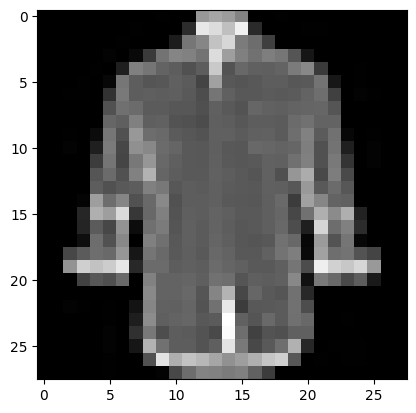

Predicted label: Shirt, Actual label: Shirt


In [ ]:
idx = 2708   # this is our X_query

img = test_images[idx][np.newaxis, :, :]
actual_label = test_labels[idx]

plt.figure()
plt.imshow(img[0], cmap='gray')
plt.show()

with torch.no_grad():
    output_vector = torch.softmax(model_1(torch.tensor(img).unsqueeze(1)), dim=1).numpy()
print(f"Predicted label: {class_names[np.argmax(output_vector)]}, Actual label: {class_names[actual_label]}")

### Model Interpretability with LIME

Let's start implementing an end-to-end interpretability algorithm with LIME.

### Setting Up LIME's Two Pieces

`LimeImageExplainer` is LIME itself. `SegmentationAlgorithm('quickshift', ...)` is the **segmenter** — covered in more depth below — it carves the image into coherent regions (not individual pixels) before LIME starts perturbing it.

In [ ]:
from lime import lime_image                                              # since image is the input; lime_text also exists
from lime.wrappers.scikit_image import SegmentationAlgorithm             # this is our interpretable model (as discussed above)

explainer = lime_image.LimeImageExplainer(verbose=False)
segmenter = SegmentationAlgorithm('quickshift', kernel_size=1, max_dist=200, ratio=0.2)

LIME's image explainer expects RGB images, so we convert our single-channel grayscale image to a 3-channel RGB-shaped array (even though all 3 channels will hold the same grayscale value).

In [ ]:
# LIME's image explainer works with RGB images, so we need a way to convert between the two
from skimage.color import gray2rgb, rgb2gray, label2rgb

img2 = gray2rgb(img[0])
print(img2.shape)

(28, 28, 3)


**Important:** LIME calls `classifier_fn` directly, outside of PyTorch's `no_grad()` context, and it expects plain NumPy probabilities back, not tensors. The function below does three things every time LIME calls it: converts the perturbed RGB images back to grayscale, turns them into a tensor the model expects, and returns softmax probabilities as a NumPy array.

In [ ]:
def predict_on_color(images):
    global model_1
    gray = rgb2gray(images)                                       # (N, H, W)
    x = torch.tensor(gray, dtype=torch.float32).unsqueeze(1)       # (N, 1, H, W)
    with torch.no_grad():
        probs = torch.softmax(model_1(x), dim=1)
    return probs.numpy()

### Run LIME

This is the actual LIME call: perturb `img2` according to the segmenter's regions, run each perturbation through `predict_on_color`, and fit a local interpretable model — exactly the pipeline summarized above. `top_labels=10` means it computes an explanation for all 10 classes at once, so we can inspect any of them afterward without re-running LIME.

In [ ]:
%%time
explanation = explainer.explain_instance(
    img2, classifier_fn=predict_on_color,
    top_labels=10, hide_color=0, num_samples=1000, segmentation_fn=segmenter)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 246 ms, sys: 3.14 ms, total: 249 ms
Wall time: 415 ms


**Note for Instructor:** The original script used `num_samples=10000`, which can take a minute or more on a CPU during a live class. `num_samples=1000` gives very similar regions for this image in well under a second. We will come back to exactly this knob later, when we test how much it affects the stability of the explanation.

### Visualize the Explanation

`get_image_and_mask(..., positive_only=True)` returns just the regions that pushed the prediction *toward* the actual class; `positive_only=False` also shows the regions that pushed *away* from it. `label2rgb` colors the masked regions on top of the original image so we can see exactly where LIME found influence.

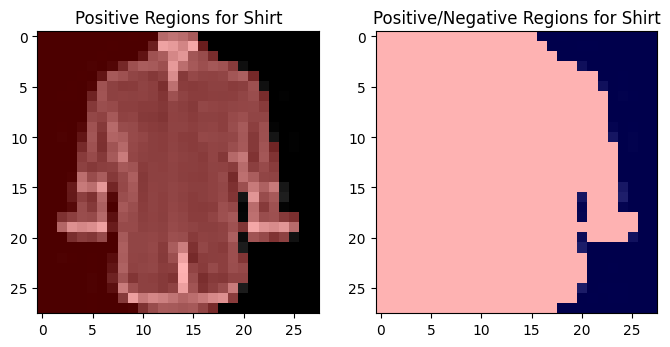

In [ ]:
temp, mask = explanation.get_image_and_mask(test_labels[idx], positive_only=True, num_features=10, hide_rest=False, min_weight=0.01)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(label2rgb(mask, temp, bg_label=0), interpolation='nearest')
ax1.set_title('Positive Regions for {}'.format(class_names[test_labels[idx]]))

temp, mask = explanation.get_image_and_mask(test_labels[idx], positive_only=False, num_features=10, hide_rest=False, min_weight=0.01)

ax2.imshow(label2rgb(3 - mask, temp, bg_label=0), interpolation='nearest')
ax2.set_title('Positive/Negative Regions for {}'.format(class_names[test_labels[idx]]))
plt.show()

**Observe**

For the image on the right, the red regions denote the vulnerable points of the model. Meaning, on creating noise in these regions, the model misclassifies.

### What Is Happening in This Code?

LIME provides two unique interfaces:
- **Segmenter** — a segmenter is responsible for dividing an instance (in our case, an image) into subregions. This allows us to detect which part of our input is most influential.
- **Explainer** — the explainer in LIME is a simpler, interpretable model that is trained to approximate the behavior of the black-box model in the local neighborhood of the instance being explained.

### Doing This for Every Class at Once

The comments in the cell walk through the idea: repeat the same positive-region extraction for all 10 classes in a loop, to see at a glance where the model's attention would need to shift to predict something else entirely.

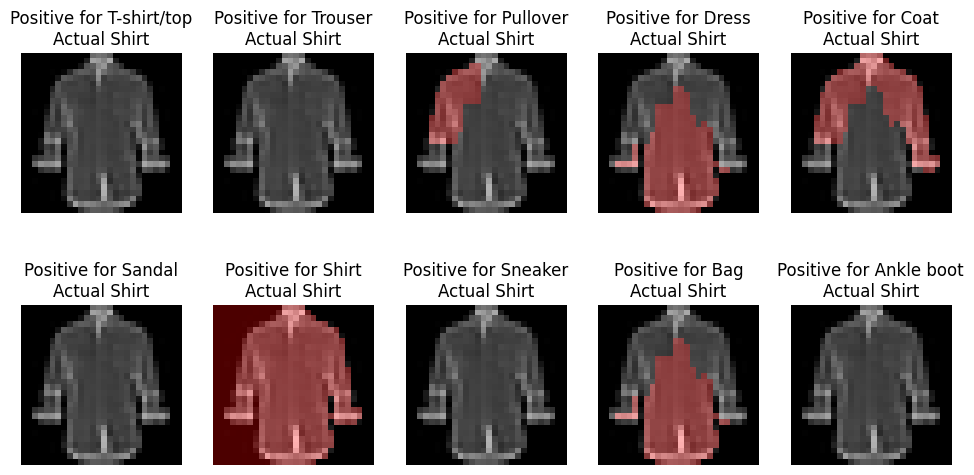

In [ ]:
# For each class, we add noise and check where the model could have been mis-led.
# What should we change in our image so that, instead of predicting Shirt, it starts predicting T-shirt/top, etc.?
# The red regions are the ones where adding noise pushes the prediction from the actual class (Shirt) toward that particular class.
fig, m_axs = plt.subplots(2, 5, figsize=(12, 6))
for i, c_ax in enumerate(m_axs.flatten()):
    temp, mask = explanation.get_image_and_mask(i, positive_only=True, num_features=1000, hide_rest=False, min_weight=0.01)
    c_ax.imshow(label2rgb(mask, img2, bg_label=0), interpolation='nearest')
    c_ax.set_title('Positive for {}\nActual {}'.format(class_names[i], class_names[test_labels[idx]]))
    c_ax.axis('off')
plt.show()

**Observe**

- The red regions show the locality of points where creating noise causes the model to misclassify.
- Notice that for Actual Shirt, Bag and Pullover, there is no red region, meaning that for these classes the model predicts absolutely correctly.

### Quiz: Reading a LIME Explanation

**Question:** In the grid of ten panels above, the panel for class "Dress" shows a large red region, but the panel for class "Bag" shows almost no red region. What does this tell us about the model's prediction on this one image?

- A. The training set simply contains more dress images than it does bag images
- B. The model is generally more accurate on dresses than it is on bags overall
- C. LIME always paints whichever class has the lowest numeric index the most red
- D. Small perturbations push this prediction toward Dress more easily than Bag

**Note for Instructor:** Run this as a chat poll. Correct option: D.

A LIME panel for a class is drawn from the segments whose perturbation pushes the model's prediction toward that class. A large red region for Dress means that changing the pixels in that region moves the model noticeably toward predicting Dress, while an almost-empty panel for Bag means no small perturbation of this image comes close to a Bag prediction. This is a statement about one image's local neighborhood, not about overall accuracy, class frequency, or any fixed ordering of classes.

## Does LIME Give the Same Answer Every Time?

LIME perturbs the image randomly and fits a local model on those random samples. That raises an uncomfortable question.

**Ask Learners:** If we run the exact same explanation on the exact same image and the exact same model twice, will LIME highlight exactly the same region both times?

Let's actually test this, instead of guessing. We explain the same image five separate times, changing nothing except LIME's internal random seed, and look at how much the importance score of the single most influential region moves.

### The Code

We explain the exact same image 5 times, changing only LIME's `random_seed` each time (and deliberately using a tiny `num_samples=50` so any instability shows up clearly), and record the importance weight of each run's single most influential region.

In [ ]:
top_weights = []
for seed in range(5):
    exp_i = lime_image.LimeImageExplainer(verbose=False)
    explanation_i = exp_i.explain_instance(
        img2, classifier_fn=predict_on_color,
        top_labels=10, hide_color=0, num_samples=50,          # a small sample count, to make the randomness visible
        segmentation_fn=segmenter, random_seed=seed)
    weights = dict(explanation_i.local_exp[test_labels[idx]])
    top_weights.append(max(weights.values()))

print("weight of the single most important region, across 5 runs:")
print([round(w, 3) for w in top_weights])
print("range:", round(max(top_weights) - min(top_weights), 3),
      " relative spread:", f"{(max(top_weights) - min(top_weights)) / max(top_weights):.0%}")

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

weight of the single most important region, across 5 runs:
[np.float64(0.507), np.float64(0.519), np.float64(0.551), np.float64(0.539), np.float64(0.546)]
range: 0.044  relative spread: 8%


With only 50 perturbation samples, the weight of the most important region swings noticeably from run to run, purely because of which random perturbations happened to be drawn. Nothing about the image or the model changed between runs.

**Ask Learners:** Does this mean LIME is broken, or useless? Type your view in the chat.

Neither. It means LIME's explanation is an **estimate**, and like any estimate built from random samples, more samples make it more stable. Go back and re-run the first explanation in this notebook with `num_samples=1000` instead of `num_samples=50` a few times, and the swing shrinks sharply. The practical lesson: **never trust a LIME explanation generated with a tiny sample count**, and when an explanation will inform a real decision, such as a hospital audit, run it more than once and look for agreement before trusting any single run.

This instability is a genuine, well-documented property of LIME, and it is exactly the kind of limitation we will see spelled out on the next slide.

### AI-Assisted Stability Check

**Step 1:** In the chat, guess how many samples you think are needed before the top region's weight stops swinging by more than 0.02 between runs.

**Step 2:** Ask an AI assistant: "I am running LIME's image explainer with `num_samples` values of 50, 200, 1000 and 5000 on the same image. Write a short loop that measures the standard deviation of the top feature's weight at each sample count, and predict the shape of the resulting curve."

**Step 3:** Adapt the loop to the `top_weights` pattern above and run it for the four sample counts.

**Step 4:** Compare the actual curve to the AI's prediction and to your own guess from Step 1. Post the sample count where the swing first drops under 0.02 in the chat.

**Note for Instructor:**
- AI role: proposes the experiment code and predicts the shape of the stability curve.
- Learner role: runs the real experiment and checks the AI's prediction against the data.
- Learning objective: understand that LIME's sample count is a knob that trades off compute time against explanation stability.
- Guardrail: the AI's predicted curve is not treated as the answer; only the executed code's output decides where the stability threshold is crossed.

## End of Part 1 — What's Next in Part 2

Today we built an image classifier, used LIME to explain one of its individual predictions, and discovered that LIME's explanations can swing noticeably from run to run when too few perturbation samples are used.

In Part 2, we'll pick up right where we left off and cover:

- **Advantages and Disadvantages of LIME** — a clear-eyed look at when to reach for it and when not to
- **SHAP** — an alternative explanation method rooted in cooperative game theory, including a from-scratch worked example and a full code implementation
- **LIME vs. SHAP** — how to choose between them